# 02 — Branch D clustering experiments

This notebook develops the first branch-specific youth typology for **Branch D — In Education**.

It uses only respondents with reliable final-route metadata:

```text
branch == "D"
branch_routing_source == "translated_final_active_branch"
```

The workflow follows the supervisor preparation plan:

- universal variables plus Branch D variables only;
- an 80/20 train–holdout split before fitting preprocessing;
- median imputation, one-hot encoding, and standardization;
- PCA retaining at least 85% of variance;
- K-Means experiments for `k=2–5`;
- elbow, silhouette, Calinski–Harabasz, Davies–Bouldin, gap, stability, and cluster-size checks;
- hierarchical clustering and Gaussian mixtures as comparison models;
- holdout validation followed by a final refit on all validated Branch D records;
- readable cluster profiles without assigning subjective names automatically.

Cluster naming and programme mapping remain researcher/expert interpretation tasks.

In [1]:
from __future__ import annotations

import json
import warnings
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)

VALUES_FILE = Path("outputs/nysc_survey_cleaned_values.csv")
LABELS_FILE = Path("outputs/nysc_survey_cleaned_labels.csv")
MANIFEST_FILE = Path("outputs/nysc_survey_feature_manifest.csv")
OUTPUT_DIR = Path("outputs/branch_d_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
PCA_VARIANCE_TARGET = 0.85
K_VALUES = list(range(2, 6))
GAP_REFERENCE_DATASETS = 20
STABILITY_SEEDS = list(range(10))
MIN_FINAL_CLUSTER_SIZE_GUIDELINE = 30
MIN_TRAIN_CLUSTER_SIZE = int(np.ceil(MIN_FINAL_CLUSTER_SIZE_GUIDELINE * (1 - TEST_SIZE)))

for path in [VALUES_FILE, LABELS_FILE, MANIFEST_FILE]:
    assert path.exists(), f"Required input is missing: {path.resolve()}"

print("Output directory:", OUTPUT_DIR.resolve())

Output directory: /Users/vimashafernando/Desktop/ClusterRP/outputs/branch_d_clustering


## 1. Load the strict Branch D cohort

The initial C20 route is retained as metadata, but selection is based on the final analysis branch. Legacy and transitional records are intentionally excluded from this first clustering experiment.

In [2]:
values_all = pd.read_csv(VALUES_FILE, low_memory=False)
labels_all = pd.read_csv(LABELS_FILE, low_memory=False)
manifest = pd.read_csv(MANIFEST_FILE)

strict_mask = (
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch")
)
values = values_all.loc[strict_mask].reset_index(drop=True)
labels = labels_all.loc[strict_mask].reset_index(drop=True)

assert len(values) == 191, f"Expected 191 validated Branch D records, found {len(values)}"
assert values["branch"].eq("D").all()
assert values["branch_routing_source"].eq("translated_final_active_branch").all()
assert values["respondent_id"].is_unique

cohort_audit = pd.Series({
    "cleaned_records_available": len(values_all),
    "validated_branch_d_records": len(values),
    "unique_respondents": values["respondent_id"].nunique(),
    "branch_changes_before_final_d": int(values["branch_changed"].astype(bool).sum()),
})
display(cohort_audit.to_frame("count"))

values.to_csv(OUTPUT_DIR / "branch_d_validated_cohort_values.csv", index=False)
labels.to_csv(OUTPUT_DIR / "branch_d_validated_cohort_labels.csv", index=False)

,count
cleaned_records_available,393
validated_branch_d_records,191
unique_respondents,191
branch_changes_before_final_d,0


## 2. Select universal and Branch D variables

Feature roles come from the preprocessing manifest. Identifiers, timestamps, route labels, and variables belonging exclusively to E/F/G are excluded. A specified field with no observed Branch D value is also excluded and documented.

In [3]:
selected_manifest = manifest[manifest["applicable_branch"].astype(str).isin(["all", "D"])].copy()
candidate_variables = [v for v in selected_manifest["variable"] if v in values.columns]
all_missing_variables = [v for v in candidate_variables if values[v].notna().sum() == 0]
feature_variables = [v for v in candidate_variables if v not in all_missing_variables]

type_by_variable = selected_manifest.set_index("variable")["type"].to_dict()
numeric_variables = [
    v for v in feature_variables
    if type_by_variable[v] in {"ordinal", "binary", "count_or_continuous"}
]
nominal_variables = [v for v in feature_variables if type_by_variable[v] == "nominal"]

feature_selection_audit = pd.Series({
    "manifest_candidates": len(candidate_variables),
    "all_missing_excluded": len(all_missing_variables),
    "model_variables": len(feature_variables),
    "numeric_ordinal_binary": len(numeric_variables),
    "nominal": len(nominal_variables),
})
display(feature_selection_audit.to_frame("count"))
print("All-missing variables excluded:", all_missing_variables)
display(selected_manifest[selected_manifest["variable"].isin(feature_variables)][
    ["variable", "type", "applicable_branch", "framework", "question_text"]
].reset_index(drop=True))

,count
manifest_candidates,53
all_missing_excluded,5
model_variables,48
numeric_ordinal_binary,25
nominal,23


All-missing variables excluded: ['reason_left_edu', 'spell1_contract', 'spell2_activity', 'spell2_is_current', 'spell3_activity']


,variable,type,applicable_branch,framework,question_text
0,age_group,ordinal,all,SWTS,What is your age?
1,gender,nominal,all,SWTS,What is your gender?
2,district,nominal,all,SWTS,Which district do you currently live in?
3,area_type,ordinal,all,SWTS,How would you describe your current place of r...
4,moved_from_origin,binary,all,SWTS,Do you live in the same area where you grew up?
5,move_reason,nominal,all,SWTS,What was the main reason you moved to your cur...
6,marital_status,nominal,all,SWTS,What is your current marital status?
7,age_first_married,count_or_continuous,all,SWTS,At what age were you first married?
8,spouse_activity,nominal,all,SWTS,What does your spouse or partner currently do?
9,has_children,binary,all,SWTS,Do you have any children?


## 3. Type-safe conversion

The internal survey codes are used for modeling. Ordinal codes retain their order, binary fields become 0/1, and nominal codes remain unordered strings for one-hot encoding.

In [4]:
MISSING_TOKENS = {"", "na", "n/a", "nan", "none", "null", "undefined", "missing"}
YES_VALUES = {"yes", "y", "true", "1", "1.0", "current"}
NO_VALUES = {"no", "n", "false", "0", "0.0", "ended"}
SPECIAL_ORDINAL_MAPS = {
    "age_group": {
        "15-17": 1, "15–17": 1, "18-21": 2, "18–21": 2, "22-25": 3,
        "22–25": 3, "25-30": 4, "26-29": 4, "26–29": 4, "26-30": 4,
        "30-35": 5, "30–35": 5,
    },
    "area_type": {
        "rural": 1, "small_town": 2, "town": 2, "metro": 3,
        "metro_suburb": 3, "large_city": 4, "city": 4, "urban": 4,
    },
}


def clean_scalar(value):
    if pd.isna(value):
        return pd.NA
    if isinstance(value, str):
        value = " ".join(value.split()).strip()
        if value.lower() in MISSING_TOKENS:
            return pd.NA
    return value


def clean_series(series):
    return series.map(clean_scalar)


def convert_numeric(series, variable, variable_type):
    cleaned = clean_series(series)
    if variable_type == "binary":
        numeric = pd.to_numeric(cleaned, errors="coerce").where(lambda x: x.isin([0, 1]))
        text = cleaned.astype("string").str.lower().str.strip()
        mapped = text.map({**{x: 1 for x in YES_VALUES}, **{x: 0 for x in NO_VALUES}})
        return numeric.combine_first(mapped).astype(float)

    numeric = pd.to_numeric(cleaned, errors="coerce")
    if variable in SPECIAL_ORDINAL_MAPS:
        text = cleaned.astype("string").str.lower().str.replace(" years", "", regex=False).str.strip()
        mapping = {str(k).lower(): v for k, v in SPECIAL_ORDINAL_MAPS[variable].items()}
        numeric = numeric.combine_first(text.map(mapping))
    return numeric.astype(float)


model_data = pd.DataFrame(index=values.index)
conversion_rows = []
for variable in numeric_variables:
    converted = convert_numeric(values[variable], variable, type_by_variable[variable])
    observed = values[variable].notna()
    conversion_rows.append({
        "variable": variable,
        "observed_before_conversion": int(observed.sum()),
        "unmapped_values": int((observed & converted.isna()).sum()),
    })
    model_data[variable] = converted

for variable in nominal_variables:
    model_data[variable] = clean_series(values[variable]).astype("string").fillna("missing").astype(str)

conversion_audit = pd.DataFrame(conversion_rows)
conversion_audit.to_csv(OUTPUT_DIR / "branch_d_numeric_conversion_audit.csv", index=False)
assert conversion_audit["unmapped_values"].sum() == 0, "Review unmapped numeric/ordinal values before clustering"
display(conversion_audit.query("unmapped_values > 0"))
print("Model input shape:", model_data.shape)

,variable,observed_before_conversion,unmapped_values


Model input shape: (191, 48)


## 4. Train–holdout split and leakage-safe preprocessing

The split occurs before imputation, encoding, standardization, and PCA. All transformations are fitted on the training respondents and then applied unchanged to the holdout respondents.

In [5]:
train_idx, holdout_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
)
X_train_raw = model_data.iloc[train_idx].reset_index(drop=True)
X_holdout_raw = model_data.iloc[holdout_idx].reset_index(drop=True)


def build_preprocessor(numeric_columns, nominal_columns):
    transformers = []
    if numeric_columns:
        transformers.append((
            "numeric",
            Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]),
            numeric_columns,
        ))
    if nominal_columns:
        transformers.append((
            "nominal",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            nominal_columns,
        ))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)


preprocessor = build_preprocessor(numeric_variables, nominal_variables)
X_train_encoded = preprocessor.fit_transform(X_train_raw)
X_holdout_encoded = preprocessor.transform(X_holdout_raw)
encoded_feature_names = preprocessor.get_feature_names_out()

# Standardize the complete expanded feature space, including one-hot indicators,
# as required by the distance-based clustering plan.
expanded_scaler = StandardScaler()
X_train_scaled = expanded_scaler.fit_transform(X_train_encoded)
X_holdout_scaled = expanded_scaler.transform(X_holdout_encoded)

pca = PCA(n_components=PCA_VARIANCE_TARGET, svd_solver="full", random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_holdout_pca = pca.transform(X_holdout_scaled)

split_summary = pd.Series({
    "training_rows": len(train_idx),
    "holdout_rows": len(holdout_idx),
    "input_variables": model_data.shape[1],
    "expanded_features": X_train_scaled.shape[1],
    "pca_components": X_train_pca.shape[1],
    "pca_variance_retained": pca.explained_variance_ratio_.sum(),
})
display(split_summary.to_frame("value"))

,value
training_rows,152.000000
holdout_rows,39.000000
input_variables,48.000000
expanded_features,193.000000
pca_components,64.000000
pca_variance_retained,0.854161


## 5. Evaluate K-Means for k = 2–5

The statistical recommendation combines separation, compactness, gap, stability, and cluster-size evidence. If no candidate satisfies the cluster-size safeguard, the notebook reports **no acceptable solution** and uses the best-ranked `k` only as a diagnostic—not as a youth typology.

In [6]:
def gap_statistic(X, k, observed_inertia, reference_count=GAP_REFERENCE_DATASETS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed + k)
    lower, upper = X.min(axis=0), X.max(axis=0)
    reference_logs = []
    for b in range(reference_count):
        reference = rng.uniform(lower, upper, size=X.shape)
        model = KMeans(n_clusters=k, n_init=20, random_state=seed + b)
        model.fit(reference)
        reference_logs.append(np.log(max(model.inertia_, np.finfo(float).eps)))
    reference_logs = np.asarray(reference_logs)
    gap = reference_logs.mean() - np.log(max(observed_inertia, np.finfo(float).eps))
    gap_se = reference_logs.std(ddof=1) * np.sqrt(1 + 1 / reference_count)
    return float(gap), float(gap_se)


evaluation_rows = []
training_models = {}
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE)
    labels_train = model.fit_predict(X_train_pca)
    training_models[k] = model

    stability_scores = []
    for seed in STABILITY_SEEDS:
        alternative = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X_train_pca)
        stability_scores.append(adjusted_rand_score(labels_train, alternative))

    gap, gap_se = gap_statistic(X_train_pca, k, model.inertia_)
    counts = pd.Series(labels_train).value_counts()
    evaluation_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_train_pca, labels_train),
        "calinski_harabasz": calinski_harabasz_score(X_train_pca, labels_train),
        "davies_bouldin": davies_bouldin_score(X_train_pca, labels_train),
        "gap": gap,
        "gap_standard_error": gap_se,
        "stability_ari_mean": float(np.mean(stability_scores)),
        "stability_ari_min": float(np.min(stability_scores)),
        "smallest_training_cluster": int(counts.min()),
        "largest_training_cluster": int(counts.max()),
    })

k_evaluation = pd.DataFrame(evaluation_rows)

# Rank metrics in their preferred directions. Cluster size is treated as a safety
# condition rather than allowing a tiny cluster to win on separation alone.
k_evaluation["eligible_size"] = k_evaluation["smallest_training_cluster"].ge(MIN_TRAIN_CLUSTER_SIZE)
for metric, ascending in {
    "silhouette": False,
    "calinski_harabasz": False,
    "davies_bouldin": True,
    "gap": False,
    "stability_ari_mean": False,
}.items():
    k_evaluation[f"rank_{metric}"] = k_evaluation[metric].rank(ascending=ascending, method="min")
k_evaluation["rank_sum"] = k_evaluation.filter(like="rank_").sum(axis=1)

eligible = k_evaluation[k_evaluation["eligible_size"]]
selection_pool = eligible if not eligible.empty else k_evaluation
diagnostic_k = int(selection_pool.sort_values(["rank_sum", "silhouette"], ascending=[True, False]).iloc[0]["k"])
recommended_k = diagnostic_k if not eligible.empty else None
valid_solution_found = recommended_k is not None
k_evaluation["statistical_recommendation"] = (
    k_evaluation["k"].eq(recommended_k) if valid_solution_found else False
)
k_evaluation["diagnostic_model"] = k_evaluation["k"].eq(diagnostic_k)
k_evaluation.to_csv(OUTPUT_DIR / "branch_d_k_evaluation.csv", index=False)

display(k_evaluation[[
    "k", "inertia", "silhouette", "calinski_harabasz", "davies_bouldin",
    "gap", "gap_standard_error", "stability_ari_mean", "smallest_training_cluster",
    "eligible_size", "rank_sum", "statistical_recommendation", "diagnostic_model",
]])
if valid_solution_found:
    print("Provisional statistical recommendation: k =", recommended_k)
else:
    print(
        "No k passed the training cluster-size safeguard of",
        MIN_TRAIN_CLUSTER_SIZE,
        "respondents. k =", diagnostic_k,
        "is retained only for diagnostic profiling."
    )

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,gap,gap_standard_error,stability_ari_mean,smallest_training_cluster,eligible_size,rank_sum,statistical_recommendation,diagnostic_model
0,2,23473.983532,0.410253,6.801322,1.954651,1.326115,0.016028,0.457307,4,False,6.0,False,True
1,3,22808.007931,0.286220,5.651965,1.915709,1.317400,0.010683,0.197573,2,False,11.0,False,False
2,4,22203.271289,0.043794,5.188287,3.329645,1.312803,0.012223,0.410609,2,False,15.0,False,False
3,5,21867.984810,0.038914,4.487643,3.177361,1.308459,0.013608,0.304171,2,False,18.0,False,False


No k passed the training cluster-size safeguard of 24 respondents. k = 2 is retained only for diagnostic profiling.


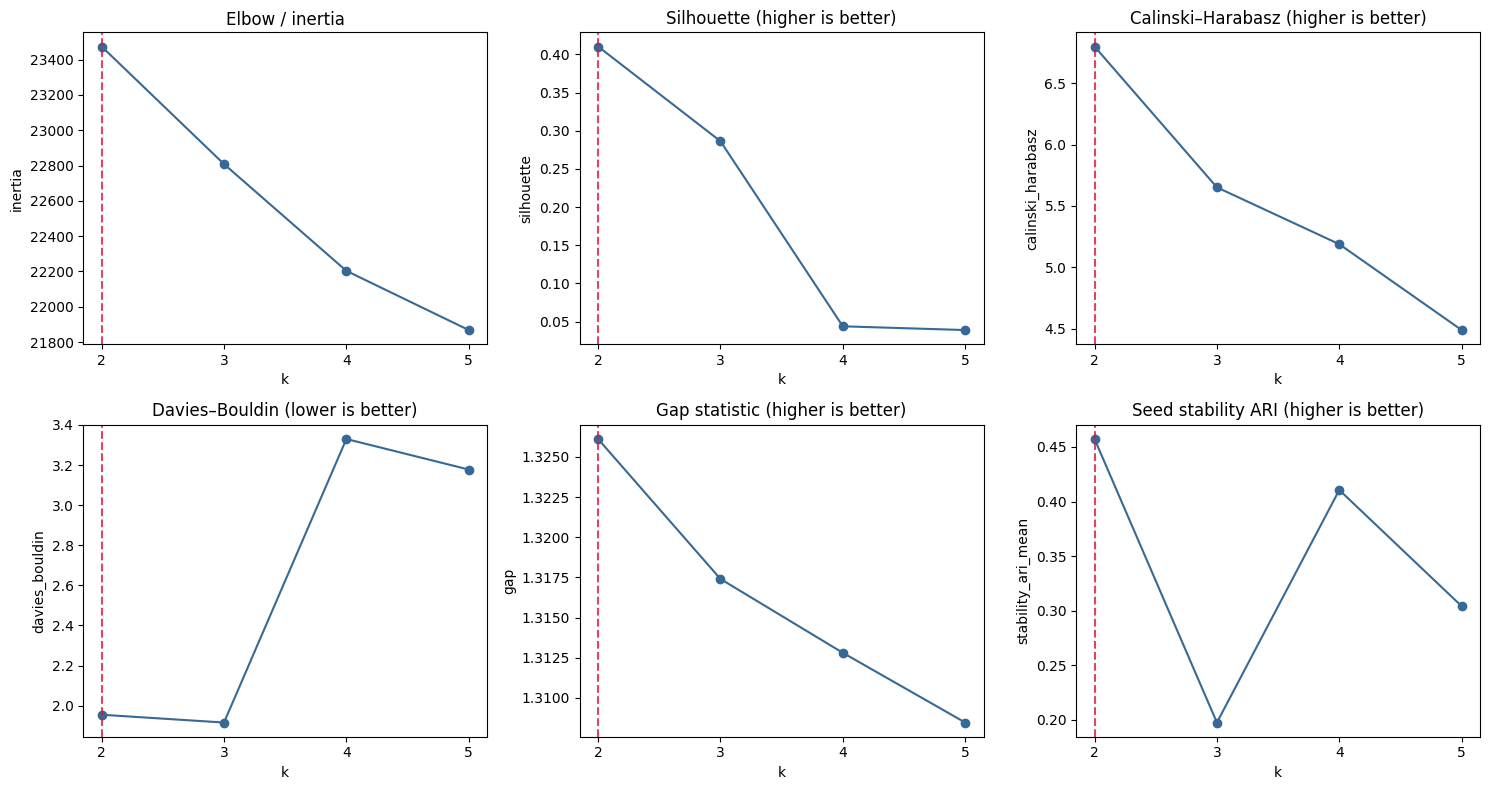

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plots = [
    ("inertia", "Elbow / inertia", False),
    ("silhouette", "Silhouette (higher is better)", True),
    ("calinski_harabasz", "Calinski–Harabasz (higher is better)", True),
    ("davies_bouldin", "Davies–Bouldin (lower is better)", False),
    ("gap", "Gap statistic (higher is better)", True),
    ("stability_ari_mean", "Seed stability ARI (higher is better)", True),
]
for ax, (column, title, _) in zip(axes.flat, plots):
    ax.plot(k_evaluation["k"], k_evaluation[column], marker="o", color="#376996")
    ax.axvline(diagnostic_k, color="crimson", linestyle="--", alpha=0.8)
    ax.set(title=title, xlabel="k", ylabel=column)
    ax.set_xticks(K_VALUES)
plt.tight_layout()
plt.show()

## 6. Compare clustering algorithms at the diagnostic k

K-Means remains the primary model because the research deliverable requires interpretable centroids and assignment of future respondents. The comparison checks whether the same `k` is reasonable under different clustering assumptions.

In [8]:
algorithm_labels = {}
algorithm_labels["K-Means"] = training_models[diagnostic_k].labels_
algorithm_labels["Hierarchical (Ward)"] = AgglomerativeClustering(
    n_clusters=diagnostic_k, linkage="ward"
).fit_predict(X_train_pca)
gmm = GaussianMixture(
    n_components=diagnostic_k, covariance_type="full", n_init=10,
    reg_covar=1e-6, random_state=RANDOM_STATE,
)
algorithm_labels["Gaussian mixture"] = gmm.fit_predict(X_train_pca)

algorithm_rows = []
for name, assigned in algorithm_labels.items():
    counts = pd.Series(assigned).value_counts()
    algorithm_rows.append({
        "algorithm": name,
        "silhouette": silhouette_score(X_train_pca, assigned),
        "calinski_harabasz": calinski_harabasz_score(X_train_pca, assigned),
        "davies_bouldin": davies_bouldin_score(X_train_pca, assigned),
        "smallest_cluster": int(counts.min()),
        "largest_cluster": int(counts.max()),
    })
algorithm_comparison = pd.DataFrame(algorithm_rows)
algorithm_comparison.to_csv(OUTPUT_DIR / "branch_d_algorithm_comparison.csv", index=False)
display(algorithm_comparison)

,algorithm,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster,largest_cluster
0,K-Means,0.410253,6.801322,1.954651,4,148
1,Hierarchical (Ward),0.401257,6.854954,2.204689,5,147
2,Gaussian mixture,0.016764,3.128685,5.703049,39,113


## 7. Holdout validation

The K-Means model is fitted only on training respondents. Holdout respondents are assigned to the nearest learned centroid, matching the validation strategy in the research plan.

In [9]:
selected_training_model = training_models[diagnostic_k]
train_clusters = selected_training_model.labels_
holdout_clusters = selected_training_model.predict(X_holdout_pca)

holdout_silhouette = (
    silhouette_score(X_holdout_pca, holdout_clusters)
    if len(np.unique(holdout_clusters)) > 1 and len(X_holdout_pca) > diagnostic_k
    else np.nan
)

validation_rows = []
for cluster in range(diagnostic_k):
    train_mask = train_clusters == cluster
    holdout_mask = holdout_clusters == cluster
    train_centroid = X_train_pca[train_mask].mean(axis=0)
    if holdout_mask.any():
        holdout_centroid = X_holdout_pca[holdout_mask].mean(axis=0)
        centroid_distance = float(np.linalg.norm(train_centroid - holdout_centroid))
    else:
        centroid_distance = np.nan
    validation_rows.append({
        "cluster": cluster,
        "training_rows": int(train_mask.sum()),
        "holdout_rows": int(holdout_mask.sum()),
        "train_holdout_centroid_distance": centroid_distance,
    })
holdout_validation = pd.DataFrame(validation_rows)
holdout_validation["combined_rows"] = holdout_validation["training_rows"] + holdout_validation["holdout_rows"]
holdout_validation.to_csv(OUTPUT_DIR / "branch_d_holdout_validation.csv", index=False)

validation_summary = pd.Series({
    "valid_solution_found": valid_solution_found,
    "recommended_k": recommended_k,
    "diagnostic_k": diagnostic_k,
    "training_silhouette": silhouette_score(X_train_pca, train_clusters),
    "holdout_silhouette": holdout_silhouette,
    "holdout_clusters_represented": len(np.unique(holdout_clusters)),
})
display(validation_summary.to_frame("value"))
display(holdout_validation)

,value
valid_solution_found,False
recommended_k,None
diagnostic_k,2
training_silhouette,0.410253
holdout_silhouette,NaN
holdout_clusters_represented,1


,cluster,training_rows,holdout_rows,train_holdout_centroid_distance,combined_rows
0,0,148,39,1.637521,187
1,1,4,0,NaN,4


## 8. Refit the diagnostic K-Means solution on all 191 respondents

Because the statistical checks may reject every candidate, this refit is explicitly diagnostic. Its assignments support investigation of the failure mode; they are not automatically accepted as final youth types.

In [10]:
final_preprocessor = build_preprocessor(numeric_variables, nominal_variables)
X_all_encoded = final_preprocessor.fit_transform(model_data)
final_feature_names = final_preprocessor.get_feature_names_out()

final_scaler = StandardScaler()
X_all_scaled = final_scaler.fit_transform(X_all_encoded)

final_pca = PCA(n_components=PCA_VARIANCE_TARGET, svd_solver="full", random_state=RANDOM_STATE)
X_all_pca = final_pca.fit_transform(X_all_scaled)

final_kmeans = KMeans(n_clusters=diagnostic_k, n_init=100, random_state=RANDOM_STATE)
final_clusters = final_kmeans.fit_predict(X_all_pca)

cluster_sizes = pd.Series(final_clusters).value_counts().sort_index().rename("rows").rename_axis("cluster").reset_index()
cluster_sizes["percentage"] = 100 * cluster_sizes["rows"] / len(values)
cluster_sizes["meets_30_respondent_guideline"] = cluster_sizes["rows"].ge(MIN_FINAL_CLUSTER_SIZE_GUIDELINE)
cluster_sizes.to_csv(OUTPUT_DIR / "branch_d_cluster_sizes.csv", index=False)

assignments = values[[
    "respondent_id", "submitted_at", "entry_branch", "branch", "branch_changed"
]].copy()
assignments["cluster"] = final_clusters
assignments["solution_status"] = "provisional" if valid_solution_found else "diagnostic_not_validated"
assignments.to_csv(OUTPUT_DIR / "branch_d_cluster_assignments.csv", index=False)

expanded_matrix = pd.DataFrame(X_all_scaled, columns=final_feature_names)
expanded_matrix.insert(0, "respondent_id", values["respondent_id"])
expanded_matrix.insert(1, "cluster", final_clusters)
expanded_matrix.to_csv(OUTPUT_DIR / "branch_d_standardized_feature_matrix.csv", index=False)

pca_columns = [f"PC{i + 1}" for i in range(X_all_pca.shape[1])]
pca_output = pd.DataFrame(X_all_pca, columns=pca_columns)
pca_output.insert(0, "respondent_id", values["respondent_id"])
pca_output.insert(1, "cluster", final_clusters)
pca_output.to_csv(OUTPUT_DIR / "branch_d_pca85.csv", index=False)

pca_summary = pd.DataFrame({
    "component": pca_columns,
    "explained_variance_ratio": final_pca.explained_variance_ratio_,
    "cumulative_variance": np.cumsum(final_pca.explained_variance_ratio_),
})
pca_summary.to_csv(OUTPUT_DIR / "branch_d_pca_summary.csv", index=False)

joblib.dump(final_preprocessor, OUTPUT_DIR / "branch_d_preprocessor.joblib")
joblib.dump(final_scaler, OUTPUT_DIR / "branch_d_expanded_scaler.joblib")
joblib.dump(final_pca, OUTPUT_DIR / "branch_d_pca.joblib")
joblib.dump(final_kmeans, OUTPUT_DIR / "branch_d_kmeans.joblib")

display(cluster_sizes)
print("Final expanded features:", X_all_scaled.shape[1])
print("Final PCA components:", X_all_pca.shape[1])
print("Final PCA variance retained:", f"{final_pca.explained_variance_ratio_.sum():.2%}")

,cluster,rows,percentage,meets_30_respondent_guideline
0,0,183,95.811518,True
1,1,8,4.188482,False


Final expanded features: 197
Final PCA components: 71
Final PCA variance retained: 85.13%


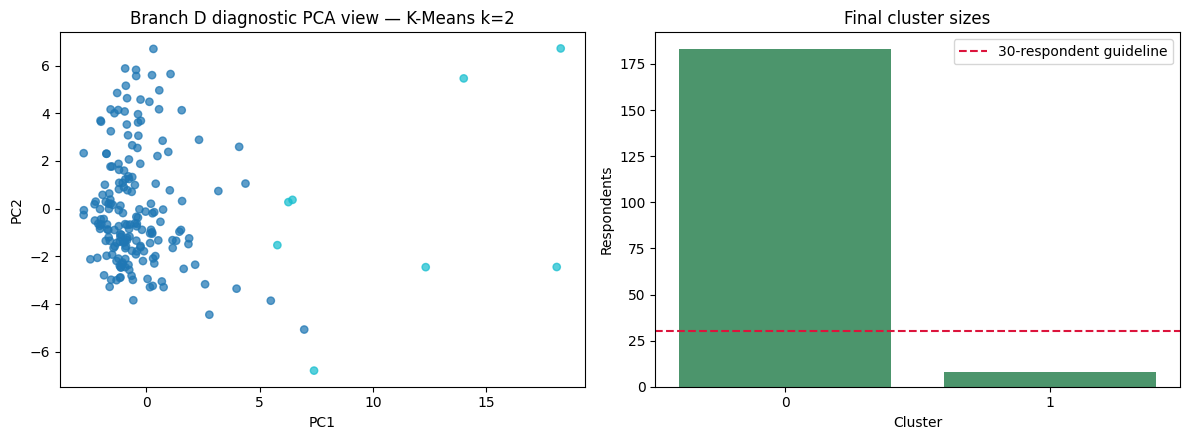

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = plt.cm.tab10(final_clusters / max(diagnostic_k - 1, 1))
axes[0].scatter(X_all_pca[:, 0], X_all_pca[:, 1], c=colors, alpha=0.72, s=28)
axes[0].set(title=f"Branch D diagnostic PCA view — K-Means k={diagnostic_k}", xlabel="PC1", ylabel="PC2")
axes[1].bar(cluster_sizes["cluster"].astype(str), cluster_sizes["rows"], color="#4C956C")
axes[1].axhline(MIN_FINAL_CLUSTER_SIZE_GUIDELINE, color="crimson", linestyle="--", label="30-respondent guideline")
axes[1].set(title="Final cluster sizes", xlabel="Cluster", ylabel="Respondents")
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Profile the clusters

The tables below support interpretation without manufacturing labels. Standardized expanded features identify what most distinguishes each cluster, while readable modes show the dominant survey answers.

In [12]:
# Expanded-feature means: positive values mean above-average presence/value;
# negative values mean below-average presence/value.
profile_matrix = pd.DataFrame(X_all_scaled, columns=final_feature_names)
profile_matrix["cluster"] = final_clusters
expanded_cluster_means = profile_matrix.groupby("cluster").mean()
expanded_cluster_means.to_csv(OUTPUT_DIR / "branch_d_expanded_feature_means.csv")

distinguishing_rows = []
for cluster in range(diagnostic_k):
    ranked = expanded_cluster_means.loc[cluster].sort_values(key=np.abs, ascending=False).head(15)
    for rank, (feature, standardized_mean) in enumerate(ranked.items(), start=1):
        distinguishing_rows.append({
            "cluster": cluster,
            "rank": rank,
            "feature": feature,
            "standardized_cluster_mean": standardized_mean,
            "direction": "above overall" if standardized_mean > 0 else "below overall",
        })
distinguishing_features = pd.DataFrame(distinguishing_rows)
distinguishing_features.to_csv(OUTPUT_DIR / "branch_d_distinguishing_features.csv", index=False)


def mode_or_missing(series):
    observed = series.dropna().astype(str)
    if observed.empty:
        return pd.NA
    return observed.mode().iloc[0]


readable = pd.DataFrame(index=labels.index)
for variable in feature_variables:
    readable[variable] = clean_series(labels[variable]).combine_first(clean_series(values[variable]))
readable["cluster"] = final_clusters

mode_rows = []
for cluster in range(diagnostic_k):
    group = readable[readable["cluster"].eq(cluster)]
    for variable in feature_variables:
        mode_rows.append({
            "cluster": cluster,
            "variable": variable,
            "readable_mode": mode_or_missing(group[variable]),
            "observed_rows": int(group[variable].notna().sum()),
        })
readable_modes = pd.DataFrame(mode_rows)
readable_modes.to_csv(OUTPUT_DIR / "branch_d_readable_modes.csv", index=False)

# Numeric/ordinal profiles in original survey-code space.
numeric_profile_data = pd.DataFrame({v: model_data[v] for v in numeric_variables})
numeric_profile_data["cluster"] = final_clusters
numeric_profile = numeric_profile_data.groupby("cluster").agg(["mean", "median", "count"])
numeric_profile.columns = [f"{variable}__{stat}" for variable, stat in numeric_profile.columns]
numeric_profile.to_csv(OUTPUT_DIR / "branch_d_numeric_profile.csv")

display(distinguishing_features.groupby("cluster").head(8))
display(readable_modes[readable_modes["variable"].isin([
    "plans_after_education", "study_field_preference", "study_motivation_type",
    "autonomy_in_study", "competence_in_study_field", "relatedness_at_institution",
    "household_income", "employment_network_quality", "ideal_sector",
])].pivot(index="variable", columns="cluster", values="readable_mode"))

,cluster,rank,feature,standardized_cluster_mean,direction
0,0,1,edu_status_never,-0.126323,below overall
1,0,2,marital_status_married,-0.126323,below overall
2,0,3,spouse_activity_missing,0.126323,above overall
3,0,4,edu_status_studying_postgrad,-0.108092,below overall
4,0,5,study_field_preference_missing,-0.108092,below overall
5,0,6,marital_status_never,0.107801,above overall
6,0,7,re_entered_education,-0.107740,below overall
7,0,8,reason_re_entered_missing,0.107740,above overall
15,1,1,edu_status_never,2.889634,above overall
16,1,2,marital_status_married,2.889634,above overall


cluster,0,1
variable,,
autonomy_in_study,A great deal — I have real freedom to shape my...,A great deal — I have real freedom to shape my...
competence_in_study_field,Fairly capable — mostly confident with some gaps,Very capable — confident and effective in my f...
employment_network_quality,Yes — I know one or two people who might help,Yes — I know several people with useful connec...
household_income,"Above LKR 200,000","Above LKR 200,000"
ideal_sector,Information technology and communications,Education and teaching
plans_after_education,Look for a job,Start my own business
relatedness_at_institution,Somewhat — I have some connections but am not ...,Strongly — genuinely connected and part of the...
study_field_preference,ICT or computing,"Commerce, business, or management"
study_motivation_type,It aligns with my own goals and will lead to w...,I am genuinely passionate about this subject


## 10. Save the experiment summary and decision notes

In [13]:
summary = {
    "cohort_definition": {
        "branch": "D",
        "branch_routing_source": "translated_final_active_branch",
        "records": int(len(values)),
    },
    "split": {
        "training_records": int(len(train_idx)),
        "holdout_records": int(len(holdout_idx)),
        "random_state": RANDOM_STATE,
    },
    "features": {
        "input_variables": int(len(feature_variables)),
        "numeric_ordinal_binary": int(len(numeric_variables)),
        "nominal": int(len(nominal_variables)),
        "all_missing_excluded": all_missing_variables,
        "final_expanded_features": int(X_all_scaled.shape[1]),
    },
    "pca": {
        "variance_target": PCA_VARIANCE_TARGET,
        "components": int(X_all_pca.shape[1]),
        "variance_retained": float(final_pca.explained_variance_ratio_.sum()),
    },
    "clustering": {
        "tested_k": K_VALUES,
        "valid_statistical_solution_found": valid_solution_found,
        "provisional_recommended_k": recommended_k,
        "diagnostic_k": diagnostic_k,
        "algorithm": "K-Means",
        "cluster_sizes": {str(int(r.cluster)): int(r.rows) for r in cluster_sizes.itertuples()},
        "all_clusters_meet_30_respondent_guideline": bool(cluster_sizes["meets_30_respondent_guideline"].all()),
    },
    "validation": {
        "training_silhouette": float(silhouette_score(X_train_pca, train_clusters)),
        "holdout_silhouette": None if pd.isna(holdout_silhouette) else float(holdout_silhouette),
        "holdout_clusters_represented": int(len(np.unique(holdout_clusters))),
    },
    "interpretation_status": (
        "Provisional statistical solution; review profiles before naming or programme mapping."
        if valid_solution_found
        else "No acceptable k found; diagnostic assignments must not be treated as a youth typology."
    ),
}

with open(OUTPUT_DIR / "branch_d_clustering_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

display(pd.Series({
    "validated respondents": summary["cohort_definition"]["records"],
    "valid statistical solution": valid_solution_found,
    "provisional k": recommended_k,
    "diagnostic k": diagnostic_k,
    "cluster sizes": summary["clustering"]["cluster_sizes"],
    "all clusters >= 30": summary["clustering"]["all_clusters_meet_30_respondent_guideline"],
    "PCA components": summary["pca"]["components"],
    "PCA variance": summary["pca"]["variance_retained"],
    "training silhouette": summary["validation"]["training_silhouette"],
    "holdout silhouette": summary["validation"]["holdout_silhouette"],
}).to_frame("result"))

,result
validated respondents,191
valid statistical solution,False
provisional k,None
diagnostic k,2
cluster sizes,"{'0': 183, '1': 8}"
all clusters >= 30,False
PCA components,71
PCA variance,0.851278
training silhouette,0.410253
holdout silhouette,None


## Interpretation checkpoint

Before assigning names:

1. Confirm that the recommended `k` is supported by several metrics, not silhouette alone.
2. Confirm that every cluster is large enough for defensible profiling.
3. Review the distinguishing-feature and readable-mode tables for coherent education, capital, and motivation patterns.
4. Discuss the provisional profiles with NYSC/domain experts.
5. Only then assign descriptive names and map clusters to programme categories.

If the profiles are incoherent, revisit feature selection, rare categories, PCA retention, or `k`; do not force a narrative onto weak clusters.